# Student Performance Prediction

Internship Project: Artificial Intelligence and Machine Learning

##Objective
The objective of this project is to predict a student's final mathematics grade using study time, absences, and previous grades.

## Technologies Used
- Python
- Pandas
- Matplotlib
- Scikit-learn
- UCI Student Performance Dataset

## Machine Learning Algorithm
Linear Regression

In [1]:
!pip -q install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Student Performance dataset
student_data = fetch_ucirepo(id=320)

# Get student features
df_real = student_data.data.features.copy()

# Add the final mathematics grade
df_real["G3"] = student_data.data.targets["G3"]

# Display the first five rows
print("Dataset loaded successfully!")
print("Dataset shape:", df_real.shape)
display(df_real.head())

Dataset loaded successfully!
Dataset shape: (649, 31)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,4,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,2,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,6,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,0,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,0,13


In [3]:
# Select the input features
X = df_real[["studytime", "absences"]].copy()

# Add the first and second period grades
X["G1"] = student_data.data.targets["G1"]
X["G2"] = student_data.data.targets["G2"]

# Select the target (final grade)
y = df_real["G3"]

print("Input features selected successfully!")
print("\nFeatures (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Input features selected successfully!

Features (X):


,studytime,absences,G1,G2
0,2,4,0,11
1,2,2,9,11
2,2,6,12,13
3,3,0,14,14
4,2,0,11,13



Target (y):


,G3
0,11
1,11
2,12
3,14
4,13



Input shape: (649, 4)
Target shape: (649,)


In [4]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Data split completed successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Data split completed successfully!
Training samples: 519
Testing samples: 130
Training features shape: (519, 4)
Testing features shape: (130, 4)


In [5]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [6]:
# Predict final grades for the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R2):", round(r2, 3))

MODEL EVALUATION RESULTS
------------------------
Mean Absolute Error (MAE): 0.75
Root Mean Squared Error (RMSE): 1.17
R-squared (R2): 0.859


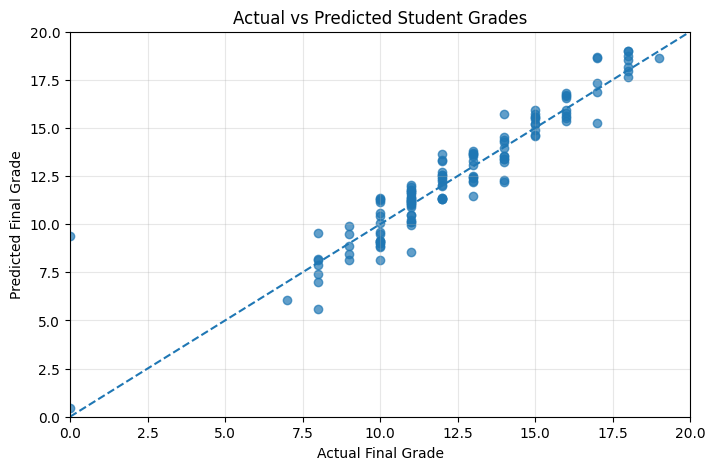

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([0, 20], [0, 20], linestyle="--")

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(alpha=0.3)
plt.show()

In [8]:
# Example student details
student = pd.DataFrame([{
    "studytime": 2,
    "absences": 3,
    "G1": 12,
    "G2": 13
}])

# Predict the final grade
predicted_grade = model.predict(student)[0]

# Display the result
print("Student Performance Prediction")
print("------------------------------")
print("Study time category:", 2)
print("Absences:", 3)
print("First period grade (G1):", 12)
print("Second period grade (G2):", 13)
print("Predicted final grade (G3):", round(predicted_grade, 2))

Student Performance Prediction
------------------------------
Study time category: 2
Absences: 3
First period grade (G1): 12
Second period grade (G2): 13
Predicted final grade (G3): 13.29


## Conclusion

The Student Performance Prediction project was developed using Python and the Linear Regression machine learning algorithm. The UCI Student Performance dataset was used to train and test the model.

The model uses study time, number of absences, first-period grade (G1), and second-period grade (G2) to predict the final mathematics grade (G3).

The model achieved a Mean Absolute Error (MAE) of 0.75, a Root Mean Squared Error (RMSE) of 1.17, and an R-squared (R²) score of 0.859 on the test set.

The project demonstrates how machine learning can be used to estimate student academic performance from available data.

## Limitations

- Predictions are estimates and may differ from actual grades.
- The dataset represents students from two Portuguese secondary schools, so results may not generalize to all students.
- The model uses previous grades (G1 and G2), meaning those grades must already be available.
- Study time and absences alone may not capture every factor affecting academic performance.

## Future Scope

- Build an interactive web application for entering student details.
- Compare Linear Regression with other machine learning algorithms.
- Explore additional factors that may help explain student performance.